# ElectroMioGraphy Overview

Electromyography (EMG) is a technique used to evaluate and record the electrophysiological activity produced by a person's muscles. It measures muscle response or electrical activity in response to a nerve’s stimulation of the muscle. The test is used to help detect neuromuscular abnormalities. During the test, one or more small needles (also called electrodes) are inserted through the skin into the muscle

In this practical experience, we will focus on the acquisition of EMG signals, showcasing the importance of adhering to Shannon's sampling theorem. 

## Peparation

For this experiment, the MuscleBIT sensor shown in the image is used. The system allows 6 different channels named by "Ax" to be used. Instead, the reference must be entered on port "I1". The appropriate electrodes are used to collect the signal after attaching them to the green connector. 

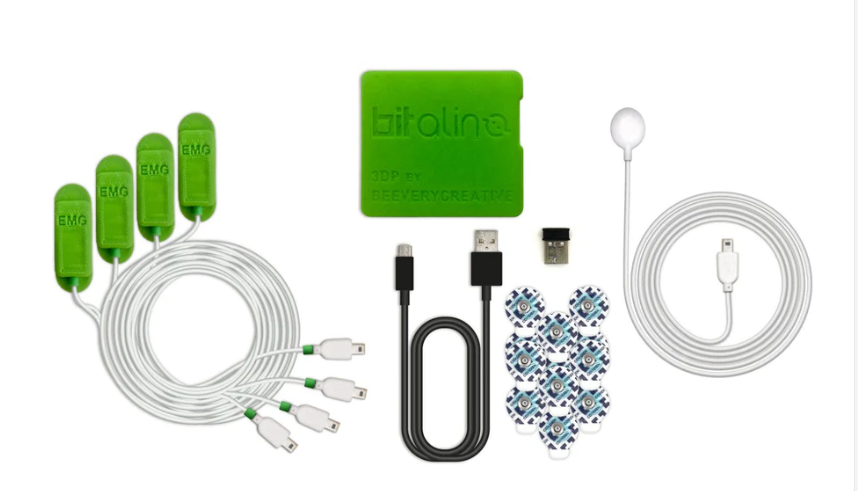

For the proper conduct of the experience, proceed as follows:
1. connect an EMG sensor to channel A1 of the device.
2. Connect the reference sensor (white) to channel I1 of the device
3. Connect the bluetooth connector to your computer
4. Pair the device via the OpenSignals screen.

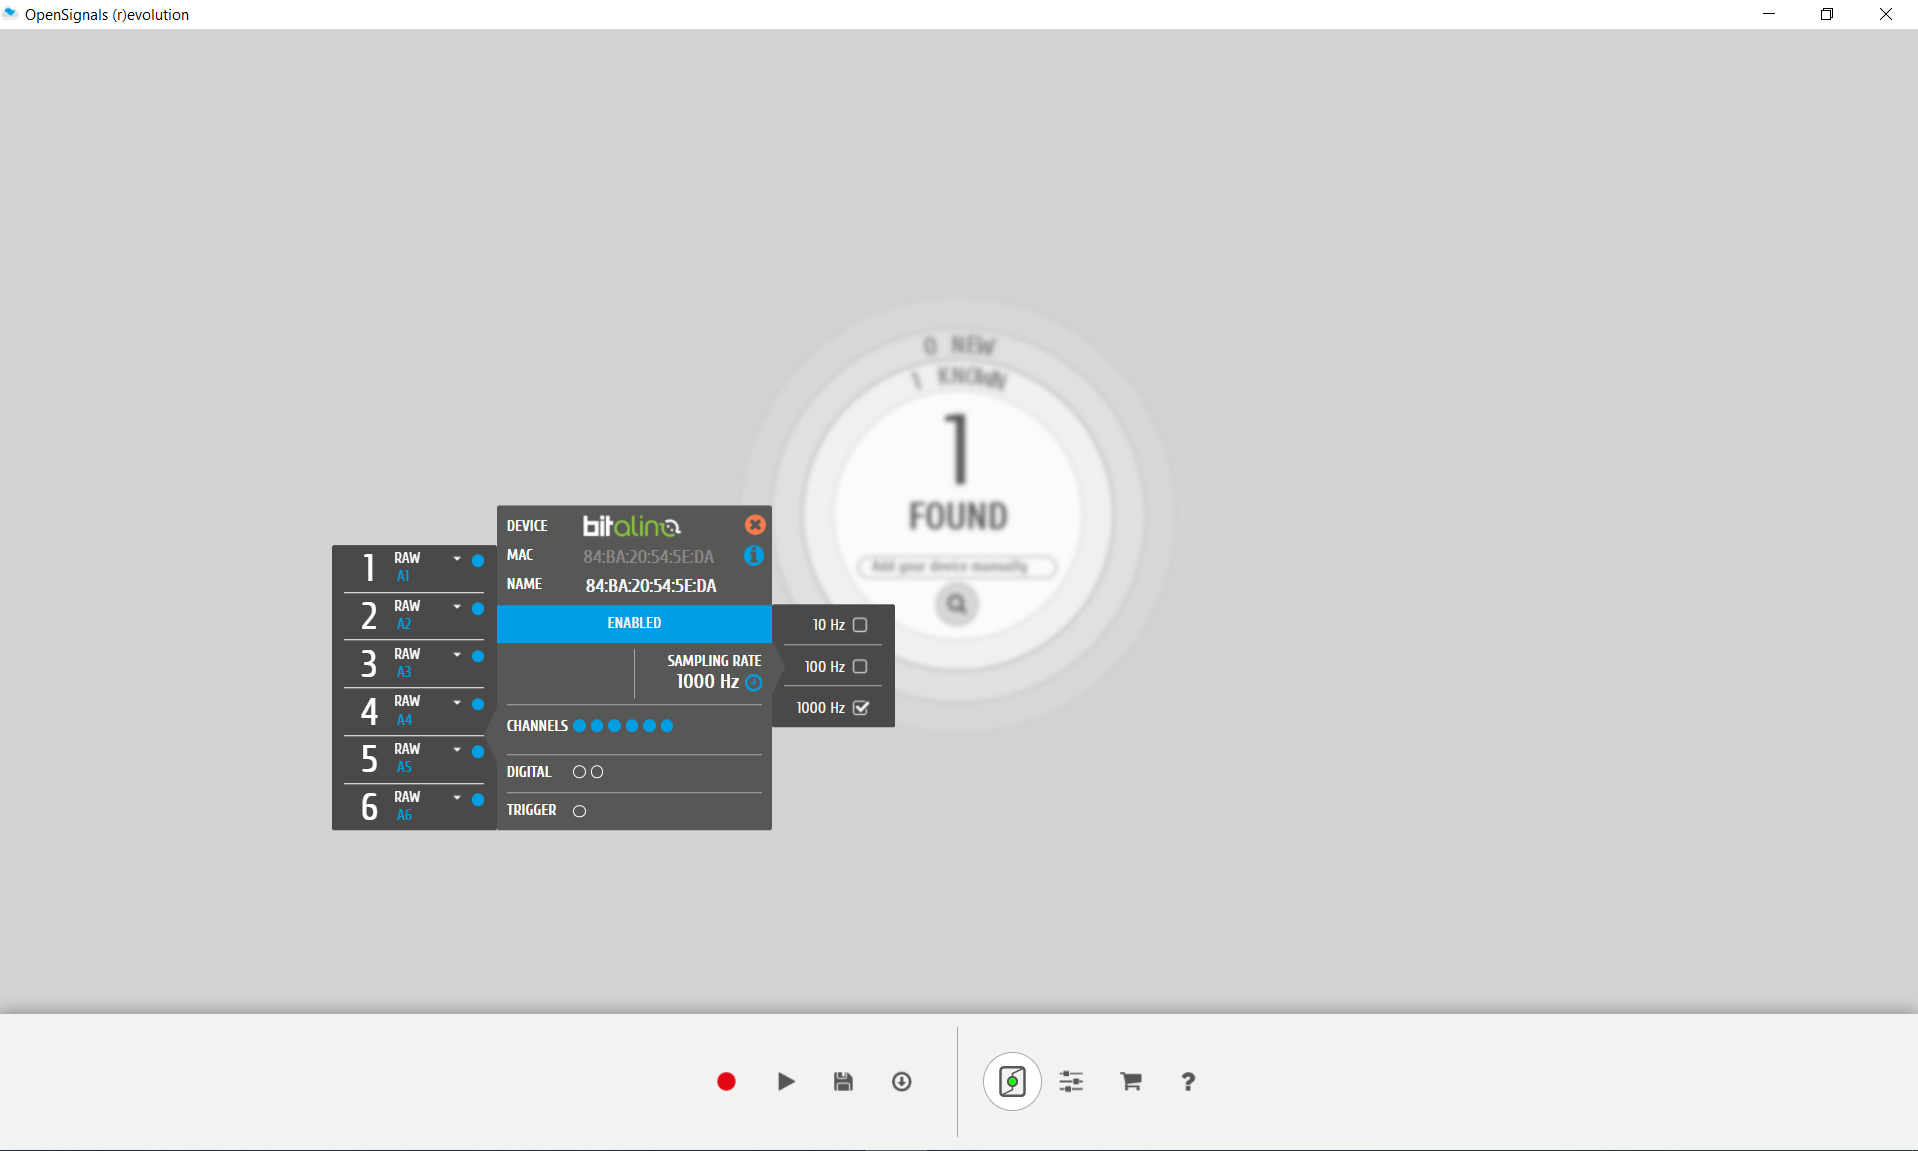

5. Set the sampling rate to 1000Hz.
6. apply the electrodes as shown in Fig. 

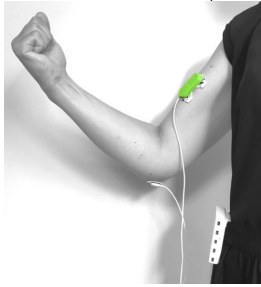

7. Click on the red button to record the biceps contraction signal. 
8. Stop the recording with the pause button in the lower right corner.
9. Save the recording in .h5, .edf, .txt format by clicking on the button with the save icon and put the file in a known location. 

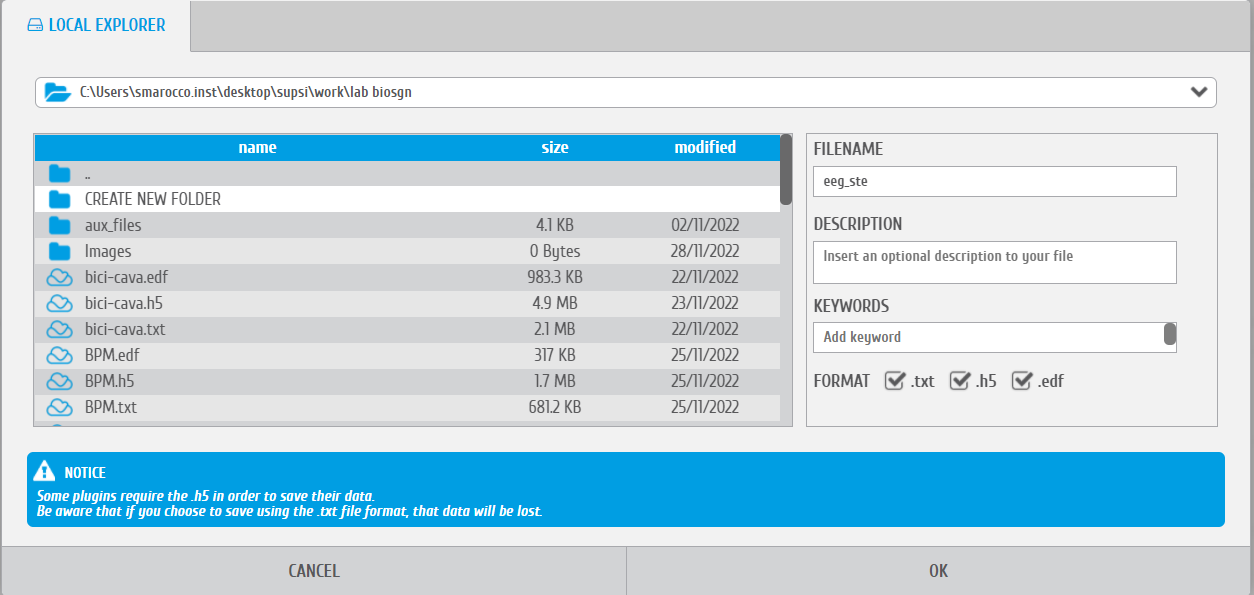

10. Go back to step 5, change the sampling rate to 100Hz and redo the acquisition trying to make the same movement. 
11. Go back to step 5 again and repeat with a sampling rate of 10 Hz. 

## Data analysis 

First step is to load the needed packages:

In [ ]:
# Biosignalsnotebooks python package
import biosignalsnotebooks as bsnb

# Package used for loading data from the input h5 file
import h5py
from h5py import File
# Scientific packages
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumtrapz
from scipy.signal import welch
from scipy import signal
from sklearn import preprocessing

To highlight the issues generated by the aliasing phenomenon, we recorded muscle movement at 1kHz, 100Hz and 10Hz sampling frequencies.

We then import the three recorded signals by entering the absolute path. 

In [ ]:
file_path_1k = ...
file_path_100 = ...
file_path_10 = ...
h5_object_1k = File(file_path_1k)
h5_object_100 = File(file_path_100)
h5_object_10 = File(file_path_10)

The objects we are going to analyze are files of type .h5.

Let us proceed to analyze the composition of the file in a hierarchical manner:

In [ ]:
# Keys list (.h5 hierarchy ground level)
print(list(h5_object_1k.keys()))

In [ ]:
h5_group_1k = h5_object_1k.get('84:BA:20:AE:BB:F8')
print ("Second hierarchy level: " + str(list(h5_group_1k)))
h5_group_100 = h5_object_100.get('84:BA:20:AE:BB:F8')
print ("Second hierarchy level: " + str(list(h5_group_1k)))
h5_group_10 = h5_object_10.get('84:BA:20:AE:BB:F8')
print ("Second hierarchy level: " + str(list(h5_group_1k)))

In [ ]:
print ("Metadata of h5_group: \n" + str(list(h5_group_1k.attrs.keys())))

Confirm that the signals have been sampled with the desired frequencies, we can access the "sampling rate" metadata. We check that the different signals are sampled as required:

In [ ]:
sampling_rate_1k = h5_group_1k.attrs.get("sampling rate")
print ("Sampling Rate: " + str(sampling_rate_1k))
sampling_rate_100 = h5_group_100.attrs.get("sampling rate")
print ("Sampling Rate: " + str(sampling_rate_100))
sampling_rate_10 = h5_group_10.attrs.get("sampling rate")
print ("Sampling Rate: " + str(sampling_rate_10))

For this experiment we are interested in manipulating data from sensors, so we are going to modify the "raw" data.  We therefore access the third hierarchical level of the data format.  

In [ ]:
h5_sub_group_1k = h5_group_1k.get("raw")
print("Third hierarchy level: " + str(list(h5_sub_group_1k)))

h5_sub_group_100 = h5_group_100.get("raw")
print("Third hierarchy level: " + str(list(h5_sub_group_100)))

h5_sub_group_10 = h5_group_10.get("raw")
print("Third hierarchy level: " + str(list(h5_sub_group_10)))

From here the recorded data for each sensor channel can be accessed. In our case we will use the data recorded on channel 1. 

To facilitate data manipulation operations we transform a nested list to a flatten list. We then generate the signal reference time using the function bsnb.generate_time(). 

In [ ]:
h5_data_1k = h5_sub_group_1k.get("channel_2")
h5_data_100 = h5_sub_group_100.get("channel_2")
h5_data_10 = h5_sub_group_10.get("channel_2")
# Conversion of a nested list to a flatten list by list-comprehension
# The following line is equivalent to:
# for sublist in h5_data:
#    for item in sublist:
#        flat_list.append(item)
signal_1k = [item for sublist in h5_data_1k for item in sublist]
signal_100 = [item for sublist in h5_data_100 for item in sublist]
signal_10 = [item for sublist in h5_data_10 for item in sublist]

def generate_times(data: list, sampling_rate: float):
    # Total time duration for the data
    total_samples = len(data)
    return np.linspace(0, total_samples / sampling_rate, total_samples)

time_1k = generate_times(signal_1k, sampling_rate_1k)
time_100 = generate_times(signal_100, sampling_rate_100)
time_10 = generate_times(signal_10, sampling_rate_10)

We create a subplot to represent the three signals with different sampling rates. 

In [ ]:
# Create three subplots to represent the signals
f, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(16,12))
ax1.plot(time_1k, signal_1k)
ax1.set_title('Signal with a sampling frequeny of 1kHz')
ax1.set_xlim([0, 4])
ax1.set_ylabel('Raw data')
ax1.grid()
ax2.plot(time_100, signal_100)
ax2.set_title('Signal with a sampling frequeny of 100Hz')
ax2.set_xlim([0, 4])
ax2.grid()
ax3.plot(time_10, signal_10)
ax3.set_title('Signal with a sampling frequeny of 10Hz')
ax3.set_xlim([0, 4])
ax3.grid()

From the datasheet function convert raw data to have values expressed in mV. 

$$ EMG(mV) = \frac{(\frac{ADC}{2^n}-0.5) \cdot VCC}{G}$$
Where
- VCC = 3V
- G = 1000
- ADC = Value sampled from the channel
- n = Number of bits of the channel

In [ ]:
# Signal Samples Conversion
VCC: int = 3_000 # 3V [mV]
G: int = 1_000
res: int = 16

signals: list = [signal_1k, signal_100, signal_10]
names: list = ["signal_1k", "signal_100", "signal_10"]

def emg(signal: list, names: list) -> float:
    return ((np.array(signal)/2**res - 0.5) * VCC) / G

signal_mV: dict = {names[0]: emg(signals[0]), names[1]: emg(signals[1]), names[2]: emg(signals[2])}

signal_mV

At this point we can assess whether the transformation has generated artifacts or whether the signal retains the original salted components. To do this we plot the manipulated signals:

In [ ]:
# Create three subplots with the converted signal
f, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(16,12))
ax1.plot(time_1k, signal_mV["signal_1k"])
ax1.set_title('Signal with a sampling frequeny of 1kHz')
ax1.set_xlim([0, 4])
ax1.grid()
ax2.plot(time_100, signal_mV["signal_100"])
ax2.set_title('Signal with a sampling frequeny of 100Hz')
ax2.set_xlim([0, 4])
ax2.grid()
ax3.plot(time_10, signal_mV["signal_10"])
ax3.set_title('Signal with a sampling frequeny of 10Hz')
ax3.set_xlim([0, 4])
ax3.grid()

It is obvious the huge difference present in the different signals, this is caused by the sampling rate used. The distortion in the last signal is caused by not following Nyquist's theorem. It defines the minimum frequency, called Nyquist frequency, required to sample an analog signal without losing information, and thus to be able to reconstruct the original continuous-time analog signal. Specifically, the theorem states that, given a function whose Fourier transform is zero outside a certain frequency range (i.e., a bandlimited signal), in its analog-to-digital conversion the minimum sampling frequency required to avoid aliasing and loss of information in reconstructing the original analog signal (i.e., in digital-to-analog reconversion) must be greater than twice its maximum frequency.  

The effects of not satisfying Nyquist's theorem are most visible in the frequency domain. Using the Fast Fourier Transform, it is possible to convert a signal from the time domain to the frequency domain. 

Before the signal FFT can be applied, however, it is necessary to perform some transformations to make the spectrum obtained from the FFT as clean as possible. 

The first step requires filtering the signal with a high pass, so as to eliminate the continuous component. We then apply a second-order high-pass Butterworth filter with a cut-off frequency of 2Hz. 

In [ ]:
# define a highpass filter

fs: float = 1_000.0     # Sample Rate [Hz]
cutoff: int = 2         # Cutoff [Hz]
nyq: float = 0.5 * fs   # Nyquist Frequency [Hz]
order: int = 2

In [ ]:
def highpass_filter(data, fs: float, cutoff: int, order: int):
    normalized_cutoff = cutoff / nyq
    # Filter coefficients
    b, a = signal.butter(order, normalized_cutoff, btype='highpass', analog=False)
    w, h = signal.freqs(b, a, worN=np.logspace(-1, 2, fs))
    y = signal.filtfilt(b, a, data)

Filter the different signals at 1k, 100, 10 Hz

In [ ]:
y_1k = highpass_filter(signal_mV["signal_1k"], 2, 1_000, 1)
y_100 = highpass_filter(signal_mV["signal_100"], 2, 100, 1)
y_10 = highpass_filter(signal_mV["signal_10"], 2, 10, 1)

The second step requires subtracting the average from the signal to eliminate any residual offsets. 

In [ ]:
...

Plot the signals without the average using subplots

In [ ]:
....

Represent the continuous spectrum of the signal using the welch( data, sampling rate) function:

In [ ]:
...

To make the representation clearer, normalise the signal spectrum:

In [ ]:
...

Represent the spectrum with subplots, placing the normalised amplitude on the y-axis and the frequencies on the x-axis.

In [ ]:
...

## Muscolar activation detection 

The second part of this experience is based on being able to detect the muscle activation. 

The first step is to rectify the signal:

In [ ]:
# [Signal Rectification]
...

Plot the signals rectified

In [ ]:
...

Smoothing of the signal provides better envelope shaping. 

A Savitzky–Golay filter is a digital filter that can be applied to a set of digital data points for the purpose of smoothing the data, that is, to increase the precision of the data without distorting the signal tendency. This is achieved, in a process known as convolution, by fitting successive sub-sets of adjacent data points with a low-degree polynomial by the method of linear least squares.



It applies the savitky-golay filter using the signal library function such as signal.savgol_filter( data, window, order, mode = 'nearest'). For the first analysis use a window of 51 and an order of 1.

In [ ]:
...

Plto the sfiltered signals

In [ ]:
...

To detect whether there has been actual muscle movement we set two thresholds, a first low threshold and a second high threshold. The high treshold can be computed with the average of the signal plus the standard deviation, for the low threshold use only the average of the signal.

In [ ]:
...

Plot the signals and the threshold for each signal in the same graph.

In [ ]:
...

In [ ]:
# Initialisation of the list that will store the start and end samples of each muscular activation period.
index_on_off=[]

# Flag that identifies when the onset was detected and the offset searching stage should begin.
flag_onset = False

# Temporary variable that will store the onset until its storage on the definitive list.
temp_onset = None

#returning the index for either onset or offset of activation
for index, sample_value in enumerate(smoothed_1k):
    # Identification of the onset index.
    if sample_value > thresh_H_1k and flag_onset is False:
        # Temporary storage of the onset index.
        temp_onset = index
        
        # Update flag.
        flag_onset = True
    # Identification of the offset index.
    elif sample_value < thresh_L_1k and flag_onset is True: 
        # Definitive storage of the onset and offset indexes.
        index_on_off.append((temp_onset, index))
        
        # Update flag.
        flag_onset = False

In [ ]:
# Initialisation of the binary signal.
binary_signal = np.zeros(len(smoothed_1k))

# Change the binary signal to 1 for all samples between the onset and offset indexes.
for onset_offset in index_on_off:
    binary_signal[onset_offset[0]:onset_offset[1]] = max(y_1k)

Scale the signal for better understanding

In [ ]:
#Scaling
...

Finally, let's plot the signals on the same graph, note how exceeding the threshold corresponds to the detection of the muscle stimulus.

In [ ]:
...

# Short-Time Fourier Transform

The Short Time Fourier Transform (STFT) is a mathematical technique employed to analyze the frequency components of signals that change over time. Unlike the traditional Fourier Transform, which gives a global view of frequency components, the STFT provides a localized perspective, allowing for the observation of how these frequencies vary temporally. By dividing a signal into short, overlapping segments and computing the Fourier Transform for each, the STFT effectively offers a time-frequency representation of the signal.

The filtering of sEMG befor analyzing the STFT is typically done with a bandpass filter with a lower cut-off frequency of 20Hz, and an upper cut-off frequency of 500Hz, Implement this filter

In [ ]:
from scipy.signal import butter, filtfilt, stft

# Define a band-pass filter
...

Filter the sEMG signal

In [ ]:
...

In [ ]:
# Adjust the parameters for STFT
nperseg = 50  # New segment length
noverlap = 25  # New overlap

# Compute the STFT with adjusted parameters for both signals
frequencies1, times1, Zxx1 = stft(...)

# Calculate the power spectrum (magnitude squared)
power_spectrum1 = np.abs(Zxx1)**2

# Convert power spectrums to dB scale
db_spectrum1 = 10 * np.log10(power_spectrum1)

Plot the power spectrum

In [ ]:
# Plot the power spectrum for both signals
plt.figure(figsize=(24, 12))

# Power spectrum for method1
plt.subplot(3, 2, 1)
plt.pcolormesh(..., ..., 10 * np.log10(power_spectrum1), shading='gouraud')
plt.colorbar(label='Intensity (dB)')
plt.title("Power Spectrum - sEMG")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

Limit the y-axis in order to better visualize the signal.

# Continuos Wavelent Transform analysis

The Continuos Wavelent Transform (CWT), in contrast to traditional Fourier-based methods, offers a flexible and adaptive resolution across both time and frequency domains. This adaptability ensures that high frequencies, which are indicative of rapid muscle activations, are finely resolved in time, while lower frequencies, typically associated with sustained muscle contractions, are more broadly represented. Given the dynamic nature of sEMG signals, where short bursts of activity often coexist with prolonged contractions, the CWT's ability to provide optimal resolution across varying frequency bands becomes invaluable.

In [ ]:
# Import necessary libraries and functions
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, cwt, morlet

# Define a band-pass filter
...

Filter the signal

In [ ]:
...

In [ ]:
# Compute the CWT using the Morlet wavelet for both signals
widths = np.arange(1, 100)
cwt_matrix1 = cwt(...)

# Calculate the power spectrum (magnitude squared)
power_cwt1 = np.abs(cwt_matrix1)**2

# Plot the wavelet power spectrum for both signals
plt.figure(figsize=(24, 12))

# Wavelet power spectrum for method1
plt.subplot(3, 2, 1)
plt.imshow(10 * np.log10(power_cwt1), aspect='auto', extent=[0, len(filtered_method1)/fs, 1, 100], origin='upper', cmap='jet')
plt.colorbar(label='Intensity (dB)')
plt.title("Wavelet Power Spectrum")
plt.xlabel("Time (s)")
plt.ylabel("Scale (Widths)")

plt.tight_layout()
plt.show()